# 01 · Multimodal · Whisper + Gemma 4 E4B + GPT-5 mini

> Demo práctica del módulo de Multimodal. Recorres las 3 modalidades (audio, vision, voz) con el stack 2026: **Whisper-large-v3-turbo** local + **Gemma 4 E4B multimodal nativo** local + **GPT-5 mini** (API de OpenAI) como referencia frontier + **gpt-4o-mini-tts** para voz.

## Qué aprendemos

1. **Speech to Text** · Whisper-base falla, Whisper-large-v3-turbo acierta · entiendes por qué importa el modelo grande.
2. **Visión local** · Gemma 4 E4B procesa imagen + texto nativamente en una T4 (4 bits).
3. **Visión frontier** · GPT-5 mini vía la API de OpenAI para comparar con la API premium.
4. **Text to Speech moderno** · `gpt-4o-mini-tts` con voice control (no el legacy TTS-1).
5. **Matriz multimodal local vs API** · cuándo elegir cada stack.

## Por qué importa

Este notebook **cierra el moat de clase-3**:

- El módulo de LLMOps te enseña a servir local con Ollama.
- Fine-tuning te enseña a fine-tunear Gemma 4 E4B.
- Evaluación te enseña a evaluarlo.
- **Multimodal (aquí)** te enseña que ese mismo Gemma 4 E4B es **multimodal nativo** · visión + audio + texto · sin pipeline separado.

Hasta hace 2 años necesitabas Whisper + LLM + TTS encadenados. En 2026 un solo modelo edge hace todo.

## Conecta con

- **Slides de Multimodal** · Realtime API actualizada (slide 11), matriz multimodal (slide 13), Gemma 4 multimodal nativo (slide 12), local vs producción (slide 14).
- **Módulo de LLMOps** · Ollama puede servir Gemma 4 multimodal · `ollama pull gemma4:e4b` corre lo mismo.
- **Fine-tuning (notebooks 03 y 05)** · es el mismo Gemma 4 E4B que fine-tuneaste · sigue siendo multimodal después del fine-tune.
- **Multimodal en producción (clase 6)** · Realtime API, voice agents, EU AI Act.

## Stack

`whisper-large-v3-turbo` (HF transformers) · `google/gemma-4-E4B-it` (multimodal nativo) · `gpt-5-mini` (visión frontier) · `gpt-4o-mini-tts` (TTS moderno).

## Hardware

T4 (Colab Free, 16 GB VRAM) vale. Cargar 2 modelos a la vez no cabe · liberamos memoria entre partes. Tiempos aproximados: Whisper carga ~1 min, Gemma 4 E4B tarda unos minutos en descargarse y cargarse (~16 GB de pesos), los demos son segundos.


---

## Setup

`transformers` + `accelerate` + `bitsandbytes` (Gemma 4-bit) + `openai` (frontier API) + `librosa` (audio).


In [ ]:
!pip install -q \
    "transformers>=5.4" \
    accelerate \
    librosa \
    soundfile \
    bitsandbytes \
    openai

   ━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━ 24.7/43.1 MB 74.4 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━ 36.8/43.1 MB 67.8 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 43.1/43.1 MB 56.5 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 43.1/43.1 MB 56.5 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.1 MB/s eta 0:00:00


### Login HuggingFace

Gemma 4 E4B requiere aceptar la licencia. Hazlo en su [model card](https://huggingface.co/google/gemma-4-E4B-it) y luego login:


In [ ]:
# Login a HuggingFace (token desde huggingface.co/settings/tokens)
from huggingface_hub import notebook_login
notebook_login()

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Audio + imágenes de ejemplo

Descargamos un MP3 (la canción de HAL 9000 "Daisy Daisy") y una imagen (carta de sushi).


In [ ]:
!wget -q https://github.com/petewarden/openai-whisper-webapp/raw/main/daisy_HAL_9000.mp3 -O daisy.mp3
!wget -q https://media-cdn.tripadvisor.com/media/photo-s/0e/8d/7a/4e/carta-de-sushi.jpg -O sushi.jpg
print("Audio + imagen listos.")

Audio + imagen listos.


---

# Parte A · Speech to Text · Whisper

Cargamos Whisper desde HuggingFace transformers (el wrapper de `pipeline` es lo más cómodo). Aquí verás una lección pedagógica clara: Whisper-base falla, Whisper-large-v3-turbo acierta.


## A.1 · Whisper-base (el modelo pequeño · ~74M params)

El modelo `base` tiene ~74M parámetros. Es rápido pero falla en audio difícil. Vamos a transcribir la célebre canción de HAL 9000 ("Daisy, Daisy, give me your answer do..."), que dura más de 30 segundos.

> **Audio de más de 30 s:** Whisper trabaja en ventanas de 30 s. Para audios más largos hay que activar la transcripción *long-form* con `return_timestamps=True` (si no, el pipeline da error).


In [ ]:
from transformers import pipeline
import torch

device = 0 if torch.cuda.is_available() else "cpu"

asr_base = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-base",
    dtype=torch.float16,
    device=device,
)

result_base = asr_base(
    "daisy.mp3",
    return_timestamps=True
)
print("Whisper-base:")
print(result_base["text"])

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  290MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.81k [00:00<?, ?B/s]

...

[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.


[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[transformers] Whisper did not predict an ending timestamp, which can happen if audio is cut off in the middle of a word. Also make sure WhisperTimeStampLogitsProcessor was used during generation.


Whisper-base:
 Take me, take me, take me, give me your answer to, I have crazy all for the love of you. It won't be a stylish marriage. My God, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, 

**Observa**: Whisper-base falla con este audio: la voz sintetizada y cantada de HAL 9000 le confunde, y es típico que confunda palabras o incluso entre en bucle repitiendo una sílaba ("oh, oh, oh..."), una alucinación frecuente de los modelos pequeños con música.

**Esa es la lectura pedagógica**: los modelos pequeños fallan en casos reales. Por eso existen los grandes.

## A.2 · Whisper-large-v3-turbo (el actual · 809M params)

`whisper-large-v3-turbo` es la versión recomendada a día de hoy:

- 809M parámetros (unas 10x más que base).
- **~8x más rápido** que `large-v3` (reduce capas del decoder de 32 a 4).
- **99 idiomas** soportados.
- Cabe de sobra en T4 (en fp16 los pesos ocupan ~1,6 GB).

Liberamos memoria de Whisper-base antes de cargar el turbo (dos a la vez no caben en T4).


In [ ]:
import gc

del asr_base
gc.collect()
torch.cuda.empty_cache()
print(f"VRAM tras liberar Whisper-base: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM tras liberar Whisper-base: 0.01 GB


In [ ]:
asr_turbo = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-large-v3-turbo",
    dtype=torch.float16,
    device=device,
)

result_turbo = asr_turbo(
    "daisy.mp3",
    return_timestamps=True
)
print("Whisper-large-v3-turbo:")
print(result_turbo["text"])

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.62GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.77k [00:00<?, ?B/s]

...

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

[transformers] Whisper did not predict an ending timestamp, which can happen if audio is cut off in the middle of a word. Also make sure WhisperTimeStampLogitsProcessor was used during generation.


Whisper-large-v3-turbo:
 Daisy, Daisy, give me your answer, too. I'm half crazy, all for the love of you. It won't be a stylish marriage. I can't afford a carriage here, but you have seen the power of the sea of a bunch of goldfish.


**Compara**: el turbo transcribe bien la mayor parte de la letra ("Daisy, Daisy, give me your answer, do..."). Aun así, fíjate en la última frase: con voz sintetizada y música todavía puede inventar palabras. Mismo audio, distinto tamaño de modelo.

**Conclusión práctica**: si vas a transcribir en producción, usa Whisper-large-v3-turbo (y revisa los audios difíciles). El base solo sirve para prototipos o *smoke tests*.

## A.3 · Detalle de idioma

Whisper detecta el idioma automáticamente. Si quieres forzarlo (mejor para audios cortos o con acento):


In [ ]:
result_en = asr_turbo(
    "daisy.mp3",
    return_timestamps=True,   # audio > 30 s: necesario para la transcripción long-form
    generate_kwargs={"language": "english", "task": "transcribe"},
)
print(result_en["text"])

[transformers] Whisper did not predict an ending timestamp, which can happen if audio is cut off in the middle of a word. Also make sure WhisperTimeStampLogitsProcessor was used during generation.


 Daisy, Daisy, give me your answer, too. I'm half crazy, all for the love of you. It won't be a stylish marriage. I can't afford a carriage here, but you have seen the power of the sea of a bunch of goldfish.


### Liberar memoria antes de la Parte B

Vamos a cargar Gemma 4 E4B (en 4 bits ocupa unos 8,7 GB de VRAM en la T4; lo imprimimos al cargarlo). Soltamos Whisper.


In [ ]:
del asr_turbo
gc.collect()
torch.cuda.empty_cache()
print(f"VRAM tras liberar Whisper-turbo: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM tras liberar Whisper-turbo: 0.01 GB


---

# Parte B · Visión local con Gemma 4 E4B multimodal nativo

**Gemma 4 E4B** es la versión edge de la familia Gemma 4 de Google: ~4,5B parámetros efectivos (8B contando los embeddings por capa). Lo importante:

- **Visión + audio + texto en un solo modelo** · no necesitas pipeline separado.
- **Edge-optimized** · en 4 bits cabe en una T4 (más abajo imprimimos la VRAM real).
- **Apache 2.0** · libre uso comercial.
- **128K tokens de contexto** · suficiente para documentos largos.

Vamos a cargarlo con `BitsAndBytesConfig` 4-bit para que entre cómodo en la T4 de Colab Free.


## B.1 · Cargar Gemma 4 E4B (multimodal)

Usamos `AutoProcessor` (entiende imagen + texto) + `AutoModelForImageTextToText`.


In [ ]:
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig
from PIL import Image

GEMMA_ID = "google/gemma-4-E4B-it"

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

processor = AutoProcessor.from_pretrained(GEMMA_ID)
model_gemma = AutoModelForImageTextToText.from_pretrained(
    GEMMA_ID,
    quantization_config=bnb,
    device_map="auto",
)

print(f"VRAM con Gemma 4 E4B 4-bit: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

processor_config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.14k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 16.0GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

VRAM con Gemma 4 E4B 4-bit: 8.67 GB


## B.2 · Demo · carta de sushi · ¿qué comer saludable?

Pasamos una imagen de una carta de sushi y preguntamos "¿qué es lo más saludable?". Buena prueba porque combina OCR (leer la carta) + razonamiento (qué es saludable).


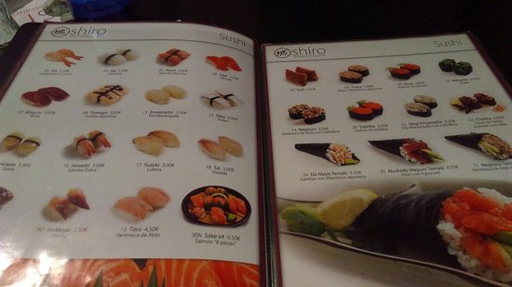

In [ ]:
image = Image.open("sushi.jpg")
image.thumbnail((512, 512))  # reducimos resolución para que la inferencia sea rápida
image

In [ ]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": "Esta es la carta de un restaurante de sushi. ¿Cuál es la opción más saludable? Responde en español con 1 sugerencia concreta de la carta."},
        ],
    },
]

inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model_gemma.device)

out = model_gemma.generate(**inputs, max_new_tokens=200, do_sample=False)
response = processor.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(response)

Basándome en la imagen de la carta, la opción más saludable probablemente sea aquella que contenga más pescado y menos acompañamientos procesados o salsas pesadas.

**Mi sugerencia concreta es:**

**"14. Mahi Mahi - 3.50€"** (o cualquier otra opción que destaque el pescado entero como el Mahi Mahi, ya que el pescado es la fuente principal de proteína magra y nutrientes en el sushi).

**Justificación:** El pescado fresco como el Mahi Mahi es una fuente excelente de proteínas magras y ácidos grasos omega-3, que son beneficiosos para la salud cardiovascular y cerebral. Es importante recordar que el sushi sigue siendo una preparación, y la cantidad de arroz o los acompañamientos pueden influir en la densidad calórica, pero el pescado es el componente más saludable de la proteína.


## B.3 · El truco · multimodal local sin coste por llamada

Lo que acabas de hacer es **visión + razonamiento sobre una imagen real**, en local, en una T4 gratis. **Coste por imagen: 0** (solo electricidad / tiempo de GPU).

Compárala con la opción API de la Parte C, donde imprimimos el coste real de la llamada. El ahorro de Gemma 4 local crece con el volumen.

### Liberar antes de la Parte C

In [ ]:
del model_gemma, processor
gc.collect()
torch.cuda.empty_cache()
print(f"VRAM tras liberar Gemma 4: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM tras liberar Gemma 4: 0.02 GB


---

# Parte C · Visión frontier · GPT-5 mini (referencia)

Mismo prompt, misma imagen, pero esta vez vía la API de OpenAI con `gpt-5-mini`. Es la **referencia frontier** que justifica que el alumno sepa cuándo vale la pena pagar.

En la familia GPT-5 la visión va integrada en el modelo (no hay variante "vision" aparte). Suele ser más preciso en razonamiento complejo, pero te factura por token: por eso imprimimos el uso y el coste de la llamada.


In [ ]:
import os
import getpass
from openai import OpenAI

os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key:")
client = OpenAI()

In [ ]:
import base64

with open("sushi.jpg", "rb") as f:
    img_b64 = base64.b64encode(f.read()).decode()

response = client.chat.completions.create(
    model="gpt-5-mini",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": "Esta es la carta de un restaurante de sushi. ¿Cuál es la opción más saludable? Responde en español con 1 sugerencia concreta de la carta."},
                {
                    "type": "image_url",
                    "image_url": {"url": f"data:image/jpeg;base64,{img_b64}"},
                },
            ],
        },
    ],
    max_completion_tokens=500,
    reasoning_effort="minimal",   # gpt-5-mini razona: sin esto el contenido puede salir vacío
)

print(response.choices[0].message.content)

# ¿Cuánto ha costado? Precios de gpt-5-mini (USD por millón de tokens, octubre 2026): 0,25 entrada · 2,00 salida
u = response.usage
coste = u.prompt_tokens * 0.25 / 1e6 + u.completion_tokens * 2.00 / 1e6
print(f"\nTokens: {u.prompt_tokens} entrada (texto + imagen) · {u.completion_tokens} salida")
print(f"Coste de esta llamada: ~{coste:.4f} USD  ->  x10.000 imágenes/mes: ~{coste*1e4:.0f} USD")

La opción más saludable suele ser aquella más baja en frituras, salsas cremosas y rebozados, y rica en pescado magro y verduras. De la carta que se ve en la foto, te sugiero concretamente: Nigiri de salmón (Sake nigiri). Es una elección alta en proteína, con grasa saludable (omega-3) y sin empanizados ni mayonesa. Si quieres aún más ligera, pide soja baja en sal y evita salsas extra.

Tokens: 254 entrada (texto + imagen) · 113 salida
Coste de esta llamada: ~0.0003 USD  ->  x10.000 imágenes/mes: ~3 USD


**Observa cómo gestiona cada modelo la duda.** La foto es pequeña (550×308 px) y algo borrosa: los nombres de los platos apenas se leen. En nuestras dos ejecuciones de validación (T4, octubre 2026) Gemma 4 E4B (decodificación *greedy*: responde siempre lo mismo) propuso con total seguridad "14. Mahi Mahi - 3.50€", un plato que no aparece en la carta. GPT-5 mini varió: una vez reconoció que no leía la carta con nitidez y dio una recomendación general (sashimi o nigiri sin salsas); la otra propuso el nigiri de salmón (*sake*), que sí está en la carta. Tus respuestas pueden variar, pero la lección se mantiene:

- Un modelo que **inventa con seguridad** es más peligroso que uno que **reconoce que no ve bien**. Verifica siempre contra la imagen.
- Con texto pequeño, la calidad de la entrada manda: una foto con más resolución mejora a los dos modelos más que cambiar de modelo.
- El coste de la llamada a la API (impreso arriba) es de fracciones de céntimo por imagen: con poco volumen, pagar la API es lo razonable; con mucho volumen o datos sensibles, gana el modelo local.


## C.1 · Comparativa Gemma 4 local vs GPT-5 mini API

| | Gemma 4 E4B local | GPT-5 mini API |
|---|---|---|
| Coste por imagen | 0 (electricidad) | el que imprime la celda anterior (céntimos de dólar o menos) |
| VRAM | la que imprimimos al cargarlo (4 bits) | 0 (es API) |
| Calidad razonamiento | buena | excelente |
| Privacidad | los datos no salen del dispositivo | los datos van a OpenAI |
| Compliance EU AI Act | más fácil (es tuyo) | hay que firmar DPA |

**Cuándo local**: volumen alto, datos sensibles, sin conexión, coste fijo.
**Cuándo API**: PoC, calidad máxima, multimodal con vídeo, voz en directo (Realtime API).

---

# Parte D · Text to Speech moderno · `gpt-4o-mini-tts`

El TTS-1 legacy (2024) sigue funcionando pero el modelo actual es `gpt-4o-mini-tts` · permite **prompt control de la voz** (entonación, tono, acento).

Vamos a convertir en voz la respuesta que acaba de darnos GPT-5 mini en la Parte C.


In [ ]:
tts_response = client.audio.speech.create(
    model="gpt-4o-mini-tts",
    voice="onyx",
    input=response.choices[0].message.content,   # la respuesta de la Parte C
    instructions="Habla con calma, tono profesional de nutricionista.",
)

with open("respuesta.mp3", "wb") as f:
    f.write(tts_response.content)

print("Audio generado: respuesta.mp3")

from IPython.display import Audio
Audio("respuesta.mp3")

Audio generado: respuesta.mp3


**Lo nuevo de `gpt-4o-mini-tts`** respecto a `tts-1`:

- **Prompt control** · el parámetro `instructions=` afecta tono y estilo de la voz.
- 6 voces (alloy, echo, fable, onyx, nova, shimmer) + nuevas en preview.
- Calidad superior, latencia similar.

Para voice agents en producción (conversacion bidireccional con latencia mínima), salta a **Realtime API** con `gpt-realtime-2` · pero eso lo profundizamos en el módulo de multimodal en producción (clase 6).


---

# Cierre · Matriz multimodal local vs API


In [ ]:
import pandas as pd

matriz = pd.DataFrame([
    {
        "Modalidad": "Speech to Text",
        "Stack local 2026": "whisper-large-v3-turbo (HF)",
        "Stack API 2026": "gpt-realtime-whisper",
        "Cuando local": "Volumen alto, privacidad, offline",
    },
    {
        "Modalidad": "Vision",
        "Stack local 2026": "Gemma 4 E4B multimodal (T4 vale)",
        "Stack API 2026": "gpt-5-mini (cheap) / gpt-5 (best)",
        "Cuando local": "Volumen >10k imgs/mes, datos sensibles",
    },
    {
        "Modalidad": "Text to Speech",
        "Stack local 2026": "Bark, XTTS-v2",
        "Stack API 2026": "gpt-4o-mini-tts (con instructions)",
        "Cuando local": "Identidad de voz custom, offline",
    },
    {
        "Modalidad": "Voice agents (S2S)",
        "Stack local 2026": "Gemma 4 E4B + Bark (pipeline)",
        "Stack API 2026": "gpt-realtime-2 (todo en 1)",
        "Cuando local": "Casi nunca · API gana en latencia",
    },
    {
        "Modalidad": "Multimodal todo-en-uno",
        "Stack local 2026": "Gemma 4 E4B (texto + img + audio)",
        "Stack API 2026": "gpt-5 (texto + img) / Realtime (voice)",
        "Cuando local": "Cuando lo prioritario es coste y privacidad",
    },
])

matriz

,Modalidad,Stack local 2026,Stack API 2026,Cuando local
0,Speech to Text,whisper-large-v3-turbo (HF),gpt-realtime-whisper,"Volumen alto, privacidad, offline"
1,Vision,Gemma 4 E4B multimodal (T4 vale),gpt-5-mini (cheap) / gpt-5 (best),"Volumen >10k imgs/mes, datos sensibles"
2,Text to Speech,"Bark, XTTS-v2",gpt-4o-mini-tts (con instructions),"Identidad de voz custom, offline"
3,Voice agents (S2S),Gemma 4 E4B + Bark (pipeline),gpt-realtime-2 (todo en 1),Casi nunca · API gana en latencia
4,Multimodal todo-en-uno,Gemma 4 E4B (texto + img + audio),gpt-5 (texto + img) / Realtime (voice),Cuando lo prioritario es coste y privacidad


## Recap

Has visto las 3 modalidades en 2 modos cada una:

- **Audio (STT)** · Whisper-base (malo, pedagógico) vs Whisper-large-v3-turbo (canónico 2026).
- **Visión** · Gemma 4 E4B local (multimodal nativo) vs GPT-5 mini API (frontier).
- **Voz (TTS)** · `gpt-4o-mini-tts` con prompt control.

Y has aterrizado la matriz multimodal local vs API.

## Hacia multimodal en producción

Este módulo cierra clase-3. El módulo de multimodal en producción (clase 6) profundiza en:

- **Realtime API** en producción · GPT-Realtime-2 + tool calling + SIP + MCP.
- **Voice agents** end-to-end · conversacion bidireccional con latencia <300ms.
- **Compliance multimodal** · EU AI Act, DPA con OpenAI, retención de datos.
- **Observabilidad multimodal** · cómo depurar pipelines audio/vision en producción.

Cuando termines ese módulo, tendrás un voice agent montado · aquí tienes los pesos · allí, el deployment.

## El moat de clase-3 cerrado

```
LLMOps (servir local con Ollama)
  +
Fine-tuning (fine-tunear Gemma 4 E4B con Unsloth)
  +
Evaluación (evaluar con lm-eval-harness)
  +
Multimodal (multimodal nativo en el mismo Gemma 4 E4B)
  =
Un modelo tuyo, multimodal, local, evaluado, coste casi cero.
```

Es la diferenciación de KEEPCODING vs cualquier curso de IA.
